# EN3160 Assignment 02 - Question 1

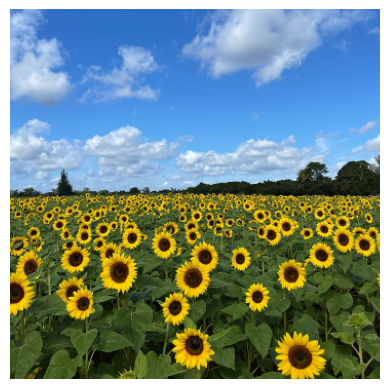

In [15]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

img = cv.imread("a2images/the_berry_farms_sunflower_field.jpeg",
                cv.IMREAD_REDUCED_COLOR_4)

assert img is not None, "Image not found"

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


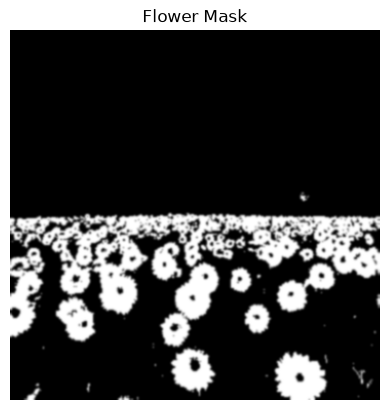

In [16]:

b, g, r = [c.astype(np.float32)/255 for c in cv.split(img)]

f = ((r > 0.95*g) & (r-b > 0.12)).astype(np.float32)
f = cv.GaussianBlur(f, (0,0), 1)

plt.imshow(f, cmap="gray")
plt.title("Flower Mask")
plt.axis("off")
plt.show()


In [17]:

sigmas = 3 * 1.2**np.arange(14)   # Approximately 3 to 32

scale_space = []

for sigma in sigmas:
    blur = cv.GaussianBlur(f, (0,0), sigma)
    lap = cv.Laplacian(blur, cv.CV_32F, ksize=3)
    scale_space.append(-sigma**2 * lap)

volume = np.array(scale_space)

print("Sigma range:", sigmas[0], "to", sigmas[-1])


Sigma range: 3.0 to 32.09796161372158


In [18]:

local_max = volume == maximum_filter(volume, size=(3,3,3))

peaks = local_max & (volume > 0.3)
peaks[0] = peaks[-1] = False

blobs = np.argwhere(peaks)

print("Candidate blobs:", len(blobs))


Candidate blobs: 104


In [19]:

candidates = sorted(
    [(x, y, np.sqrt(2)*sigmas[s], sigmas[s], volume[s,y,x])
     for s,y,x in blobs],
    key=lambda c: -c[4]
)

circles = []

for c in candidates:
    if all(np.hypot(c[0]-d[0], c[1]-d[1]) >=
           0.8*max(c[2],d[2]) for d in circles):
        circles.append(c)

circles.sort(key=lambda c: -c[2])

print("Detected circles:", len(circles))


Detected circles: 71


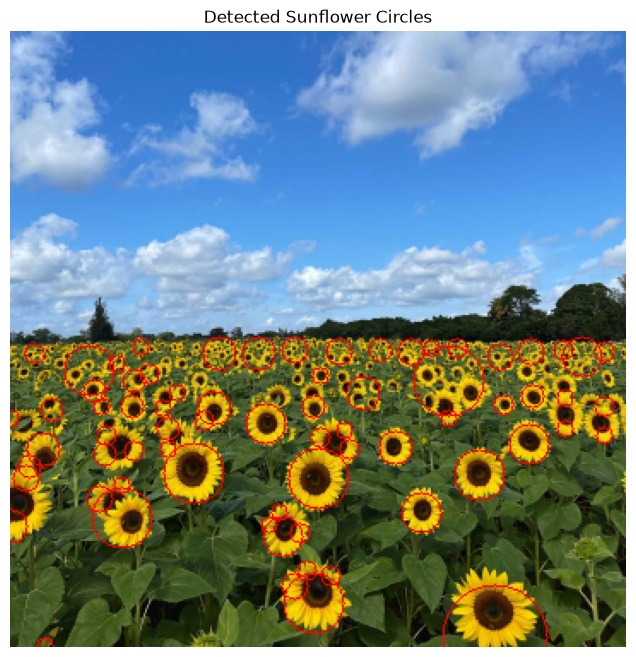

In [20]:

out = cv.cvtColor(img, cv.COLOR_BGR2RGB).copy()

for x,y,r,_,_ in circles:
    cv.circle(out, (int(x),int(y)), int(r), (255,0,0), 1)

plt.figure(figsize=(8,8))
plt.imshow(out)
plt.title("Detected Sunflower Circles")
plt.axis("off")
plt.show()


In [21]:

print("Largest 5 circles:")
print("  X    Y    Radius    Sigma")

for x,y,r,s,_ in circles[:5]:
    print(f"{x:3d}  {y:3d}   {r:6.2f}   {s:6.2f}")

print(f"\nSigma range: {sigmas[0]:.2f} to {sigmas[-1]:.2f}")


Largest 5 circles:
  X    Y    Radius    Sigma
283  354    31.52    22.29
256  204    21.89    15.48
177  334    18.24    12.90
 65  284    18.24    12.90
107  258    18.24    12.90

Sigma range: 3.00 to 32.10
